# Corner Detector & Matching

El objetivo de este laboratorio fue observar cómo influyen distintos filtros en la detección de esquinas y en el matching de imágenes. La primera parte estuvo dedicada a Harris, utilizando dos vistas de un edificio. En la segunda se probaron ORB y SIFT con fotografías de una celebridad.

Las pruebas de matching comenzaron con un retrato y una copia reducida y girada. Después se compararon dos fotografías distintas, con cambios de apariencia y de escena.

Para el desarrollo se utilizaron OpenCV, NumPy, SciPy, Matplotlib y Pillow con soporte AVIF.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
from scipy.ndimage import convolve
from PIL import Image

DATA = Path('data') / 'new_set'

def cargar(nombre):
    with Image.open(DATA / nombre) as archivo:
        imagen = np.array(archivo.convert('RGB'))
    alto, ancho = imagen.shape[:2]
    escala = min(900 / ancho, 700 / alto, 1)
    if escala < 1:
        imagen = cv2.resize(imagen, (round(ancho * escala), round(alto * escala)),
                            interpolation=cv2.INTER_AREA)
    return imagen

def mostrar(ax, imagen, titulo):
    ax.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis('off')

filtros = {
    'Sin filtro': lambda gray: gray.copy(),
    'Gaussiano': lambda gray: cv2.GaussianBlur(gray, (3, 3), 1),
    'CLAHE': lambda gray: cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray),
}
manacar = {nombre: cargar(nombre) for nombre in ['manacar.jpg', 'manacar 2.jpg']}
ana = {nombre: cargar(nombre) for nombre in ['ana.jpg', 'ana mirrored.jpg']}

## Parte 1. Detección de esquinas con Harris

El análisis comenzó con las imágenes originales y su conversión a escala de grises. A partir de esa base se probaron los filtros de entrada y se revisó la respuesta Harris. El proceso terminó con un umbral y la supresión de no máximos (NMS), para pasar de regiones candidatas a puntos concretos.

El detector conservó los gradientes Sobel y el suavizado del tensor con un kernel gaussiano de 3 × 3. La respuesta se calculó mediante $R = det(M) - k\,trace(M)^2$, con `k=0.05`. Para seleccionar las esquinas se fijaron un umbral del 1%, una ventana NMS de 7 × 7, un margen de 16 píxeles y un máximo de 500 puntos.

Las imágenes se ajustaron a un máximo de 900 × 700 píxeles para mantener ligera la demostración, sin modificar los archivos originales.

In [2]:
def harris(gray, k=0.05):
    gray = gray.astype(np.float64)
    kernel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    kernel_y = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])
    I_x = sig.convolve2d(gray, kernel_x, mode='same')
    I_y = sig.convolve2d(gray, kernel_y, mode='same')
    x, y = np.mgrid[-1:2, -1:2]
    gauss = np.exp(-(x**2 + y**2) / 2) / (2 * np.pi)
    Ixx = convolve(I_x**2, gauss)
    Ixy = convolve(I_x * I_y, gauss)
    Iyy = convolve(I_y**2, gauss)
    return Ixx * Iyy - Ixy**2 - k * (Ixx + Iyy)**2

def seleccionar_esquinas(respuesta, max_puntos=500, umbral_relativo=0.01,
                         tamano_nms=7, margen=16):
    candidatos = np.zeros(respuesta.shape, dtype=bool)
    maximo = respuesta.max()
    if maximo <= 0:
        return candidatos, []
    candidatos = respuesta > umbral_relativo * maximo
    candidatos[:margen, :] = candidatos[-margen:, :] = False
    candidatos[:, :margen] = candidatos[:, -margen:] = False
    locales = cv2.dilate(respuesta, np.ones((tamano_nms, tamano_nms), np.uint8))
    y, x = np.where(candidatos & (respuesta == locales))
    orden = np.argsort(-respuesta[y, x], kind='stable')[:max_puntos]
    return candidatos, [(int(y[i]), int(x[i])) for i in orden]


### 1.1 Imagen original y escala de grises

Como punto de partida, se colocaron las dos vistas del edificio junto a sus versiones en gris. Cada fila corresponde a una vista distinta. La conversión permitió centrar el análisis en los cambios de intensidad, que son la información utilizada por Harris para localizar esquinas.

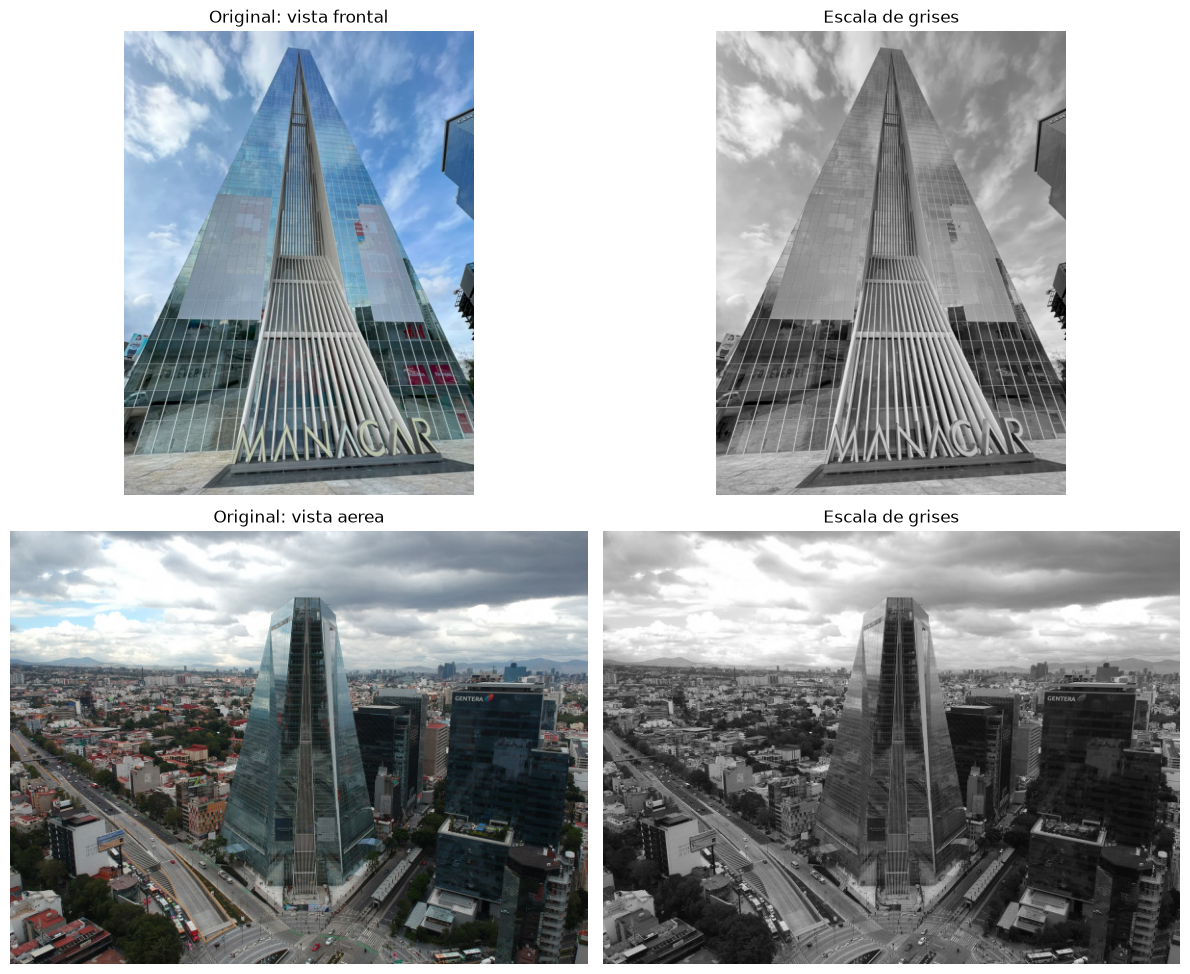

In [3]:
grises_manacar = {
    nombre: cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)
    for nombre, imagen in manacar.items()
}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for fila, (nombre, imagen) in enumerate(manacar.items()):
    vista = 'frontal' if fila == 0 else 'aerea'
    mostrar(axes[fila, 0], imagen, f'Original: vista {vista}')
    mostrar(axes[fila, 1], grises_manacar[nombre], 'Escala de grises')
plt.tight_layout()
plt.show()

### 1.2 Filtros de entrada

Sobre cada imagen en gris se prepararon tres variantes: **sin filtro**, **Gaussiano de 3 × 3 con sigma 1** y **CLAHE**. La figura sigue ese orden de izquierda a derecha. Cada variante partió de la misma entrada, sin combinar los filtros entre sí.

El Gaussiano suaviza pequeñas variaciones y ruido, aunque también puede borrar detalles útiles. CLAHE, en cambio, realza el contraste local y puede hacer más visibles tanto las estructuras como el ruido. Este preprocesamiento es independiente del suavizado del tensor dentro de Harris.

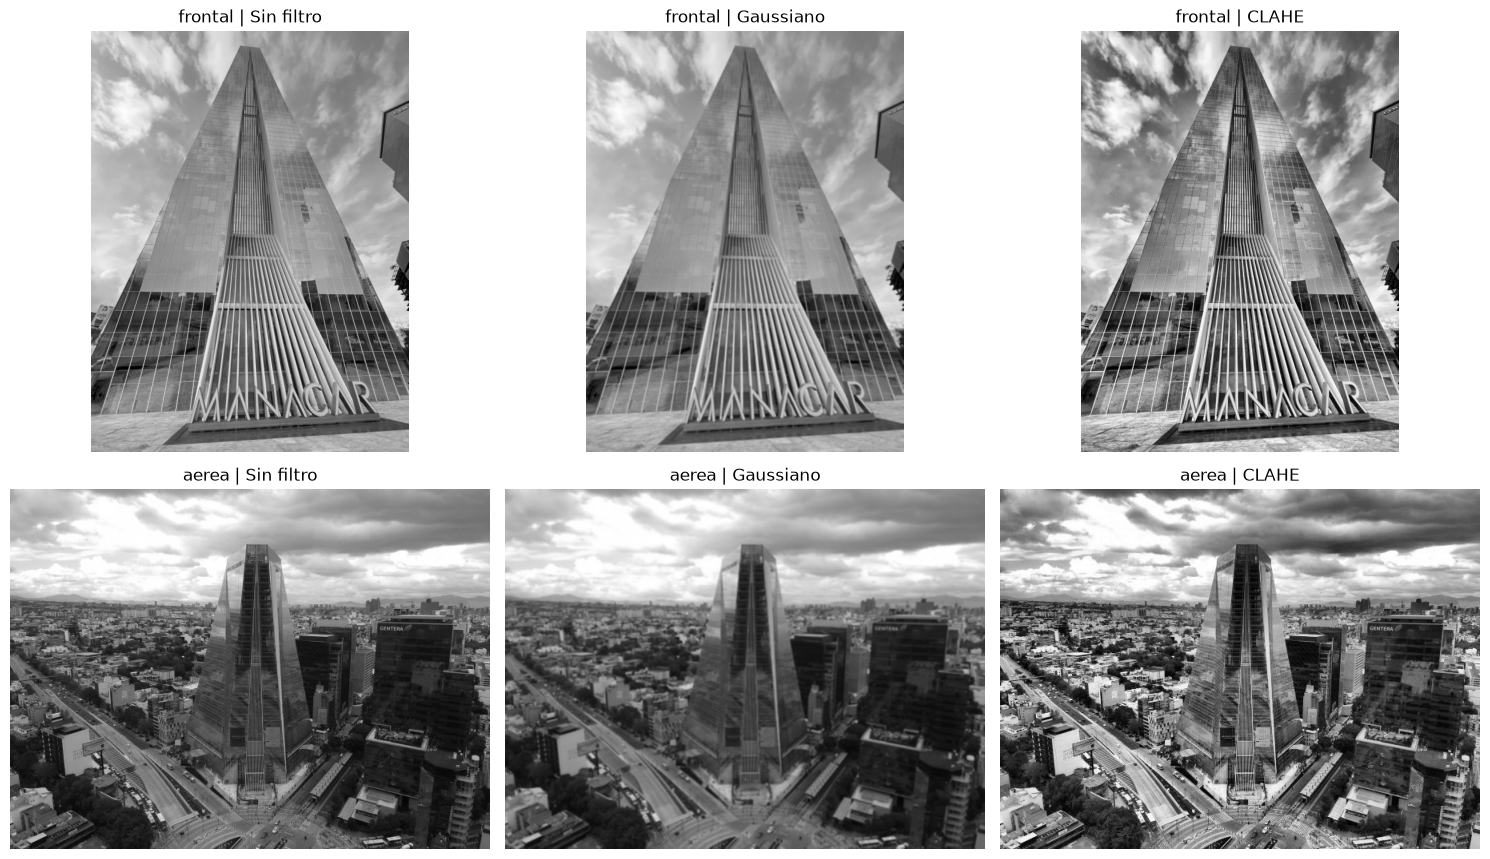

In [4]:
entradas_harris = {
    (nombre, filtro): aplicar(gris)
    for nombre, gris in grises_manacar.items()
    for filtro, aplicar in filtros.items()
}
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for fila, nombre in enumerate(manacar):
    vista = 'frontal' if fila == 0 else 'aerea'
    for col, filtro in enumerate(filtros):
        mostrar(axes[fila, col], entradas_harris[nombre, filtro],
                f'{vista} | {filtro}')
plt.tight_layout()
plt.show()

### 1.3 Respuesta Harris

Con las entradas preparadas, el siguiente paso fue calcular la respuesta Harris de la vista frontal. Para distinguir mejor las regiones candidatas, la figura presenta únicamente la parte positiva de $R$ en escala logarítmica.

Las tres variantes comparten la misma escala de color. El cambio de escala afecta solo a la visualización: el umbral se calculó sobre los valores originales de la respuesta.

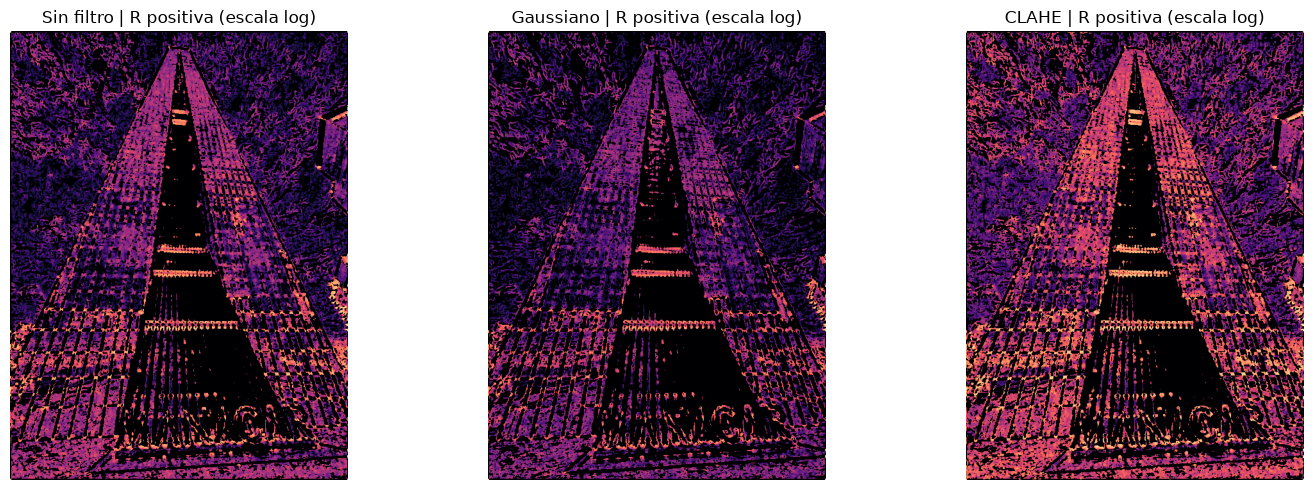

In [5]:
respuestas_harris = {
    clave: harris(gris) for clave, gris in entradas_harris.items()
}
selecciones_harris = {
    clave: seleccionar_esquinas(respuesta)
    for clave, respuesta in respuestas_harris.items()
}
nombre_ejemplo = 'manacar.jpg'
mapas = [
    np.log1p(np.maximum(respuestas_harris[nombre_ejemplo, filtro], 0))
    for filtro in filtros
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
limite = max(mapa.max() for mapa in mapas)
for ax, filtro, mapa in zip(axes, filtros, mapas):
    ax.imshow(mapa, cmap='magma', vmin=0, vmax=limite)
    ax.set_title(f'{filtro} | R positiva (escala log)')
    ax.axis('off')
plt.tight_layout()
plt.show()

### 1.4 Umbral: candidatos

La selección inicial conservó las respuestas superiores al 1% del máximo positivo de cada variante, dejando fuera un margen de 16 píxeles alrededor de la imagen. Las regiones blancas representan los candidatos obtenidos; todavía no corresponden a esquinas aisladas.

El mismo criterio relativo permitió comparar las tres entradas, aunque no asegura una sensibilidad equivalente al ruido.

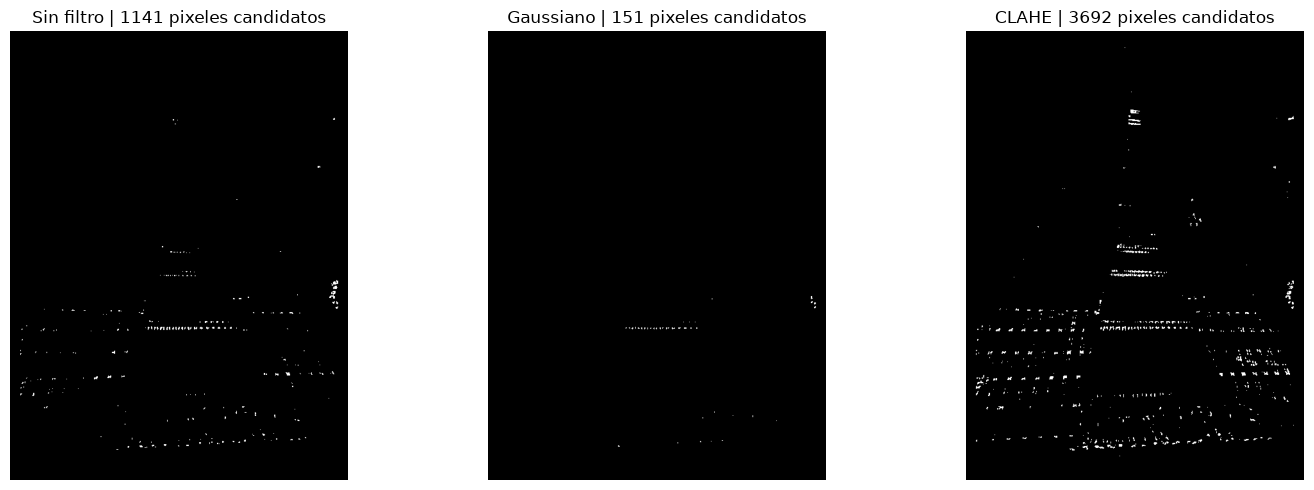

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, filtro in zip(axes, filtros):
    candidatos, _ = selecciones_harris[nombre_ejemplo, filtro]
    mostrar(ax, candidatos.astype(np.uint8) * 255,
            f'{filtro} | {np.count_nonzero(candidatos)} pixeles candidatos')
plt.tight_layout()
plt.show()

### 1.5 NMS: esquinas finales

Para obtener puntos aislados, se aplicó NMS con una ventana de 7 × 7 y se conservaron hasta 500 puntos de mayor respuesta. La figura coloca la imagen original al inicio de cada fila, seguida de las esquinas obtenidas con cada variante, dibujadas sobre esa misma fotografía.

Los títulos indican la cantidad de puntos finales, no los píxeles candidatos del paso anterior. Cuando una variante alcanza 500, el límite puede ocultar diferencias en el número de detecciones.

Esta comparación permite revisar cómo cambia la selección con el filtrado. Una mayor cantidad de puntos no garantiza mejores correspondencias: Harris localiza cambios de intensidad, no edificios completos, y requiere descriptores para realizar matching.

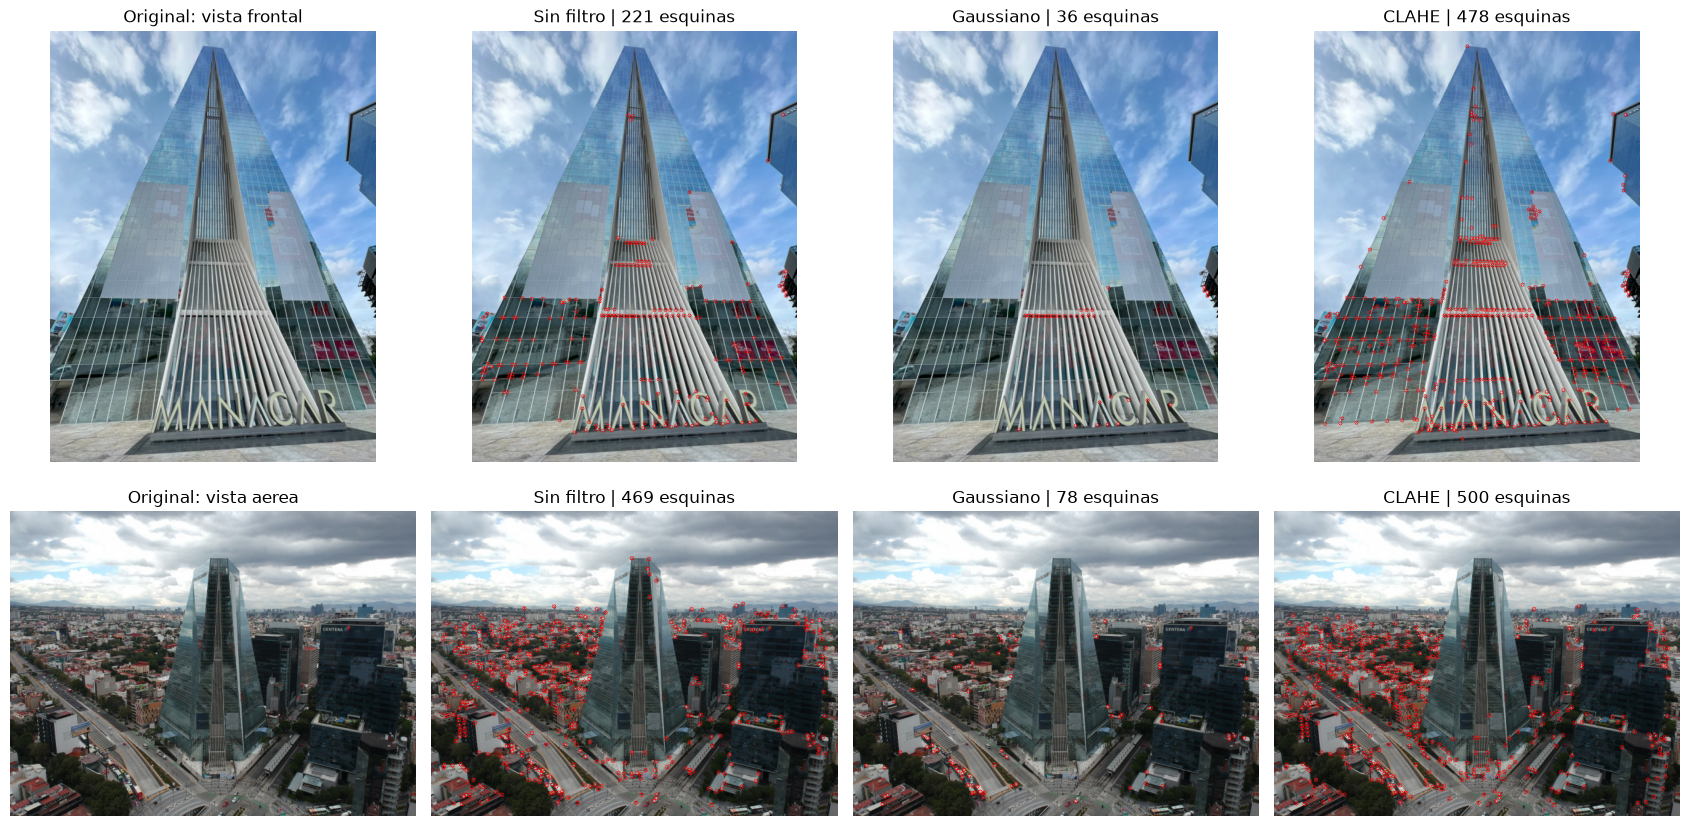

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for fila, (nombre, imagen) in enumerate(manacar.items()):
    vista = 'frontal' if fila == 0 else 'aerea'
    mostrar(axes[fila, 0], imagen, f'Original: vista {vista}')
    for col, filtro in enumerate(filtros, start=1):
        _, puntos = selecciones_harris[nombre, filtro]
        marcada = imagen.copy()
        for y, x in puntos:
            cv2.circle(marcada, (x, y), 3, (255, 0, 0), 1)
        mostrar(axes[fila, col], marcada, f'{filtro} | {len(puntos)} esquinas')
plt.tight_layout()
plt.show()

## Parte 2. Matching y comparación de filtros

La segunda parte pasó de localizar esquinas a buscar correspondencias entre imágenes. Para comenzar, se generó una copia del retrato reducida a la mitad con `pyrDown` y girada 30° con `warpAffine`.

La referencia y su copia transformada aparecen lado a lado. Ambas contienen detalles de la misma fotografía, pero con diferencias de tamaño y posición. Las zonas negras son el espacio que quedó vacío después del giro.

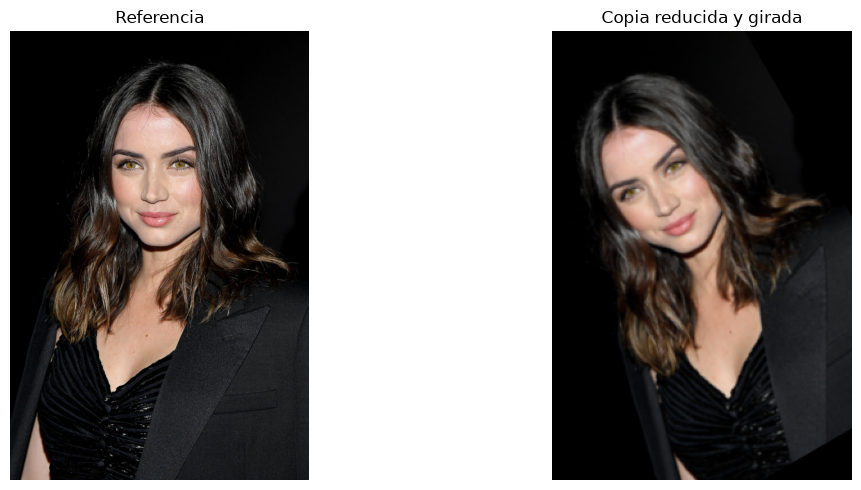

In [8]:
img_color = ana['ana.jpg']
img_gray = cv2.cvtColor(img_color, cv2.COLOR_RGB2GRAY)
test_image = cv2.pyrDown(img_color)
num_rows, num_cols = test_image.shape[:2]
rotation_matrix = cv2.getRotationMatrix2D((num_cols/2, num_rows/2), 30, 1)
test_image = cv2.warpAffine(test_image, rotation_matrix, (num_cols, num_rows))
test_gray = cv2.cvtColor(test_image, cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mostrar(axes[0], img_color, 'Referencia')
mostrar(axes[1], test_image, 'Copia reducida y girada')
plt.tight_layout()
plt.show()


### Una imagen, tres versiones

Para revisar el efecto del preprocesamiento en el matching, se retomaron las tres variantes utilizadas con Harris:

- **Sin filtro:** la imagen en gris sirvió como referencia.
- **Gaussiano:** una ventana de 3 × 3 y sigma 1 permitió suavizar la entrada, con el posible costo de perder detalles.
- **CLAHE:** el realce del contraste local quedó moderado por un límite.

El diccionario `filtros` permitió reutilizar las operaciones sin duplicar código. Cada filtro se aplicó tanto a la referencia como a la copia; la figura muestra su efecto sobre la referencia.

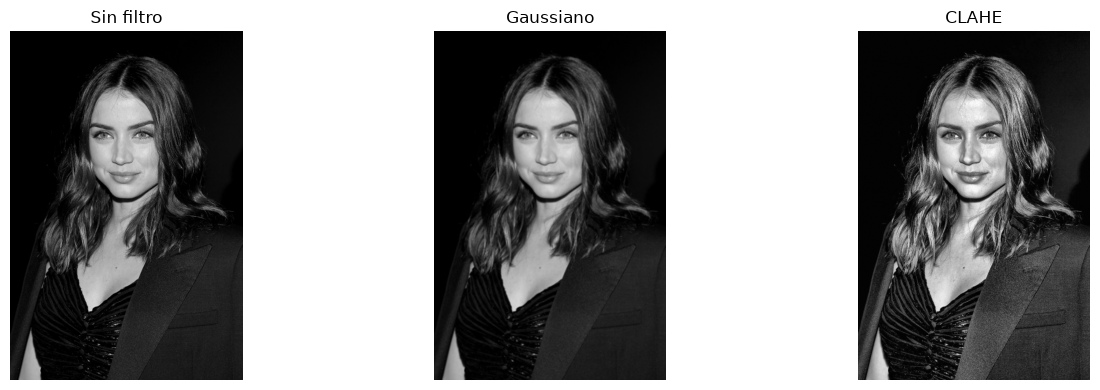

In [9]:
pares = {nombre: (aplicar(img_gray), aplicar(test_gray)) for nombre, aplicar in filtros.items()}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nombre, (referencia, copia)) in zip(axes, pares.items()):
    mostrar(ax, referencia, nombre)
plt.tight_layout()
plt.show()

### ORB frente a SIFT

La comparación entre ORB y SIFT se realizó mediante la función `matching`. Cada método detectó puntos y calculó sus descriptores; después, `BFMatcher` conservó las coincidencias recíprocas y las ordenó por distancia.

Para facilitar la lectura, las figuras incluyen solo las **20 coincidencias de menor distancia**, mientras que los títulos indican también el total encontrado. Cada fila corresponde a un filtro, con ORB a la izquierda y SIFT a la derecha.

La lectura de los resultados considera tanto la cantidad de coincidencias como los detalles conectados por las líneas. El total no equivale a una medida de exactitud: incluso una coincidencia recíproca puede ser incorrecta. Del mismo modo, el cruce de líneas puede deberse al giro y no necesariamente a un error.

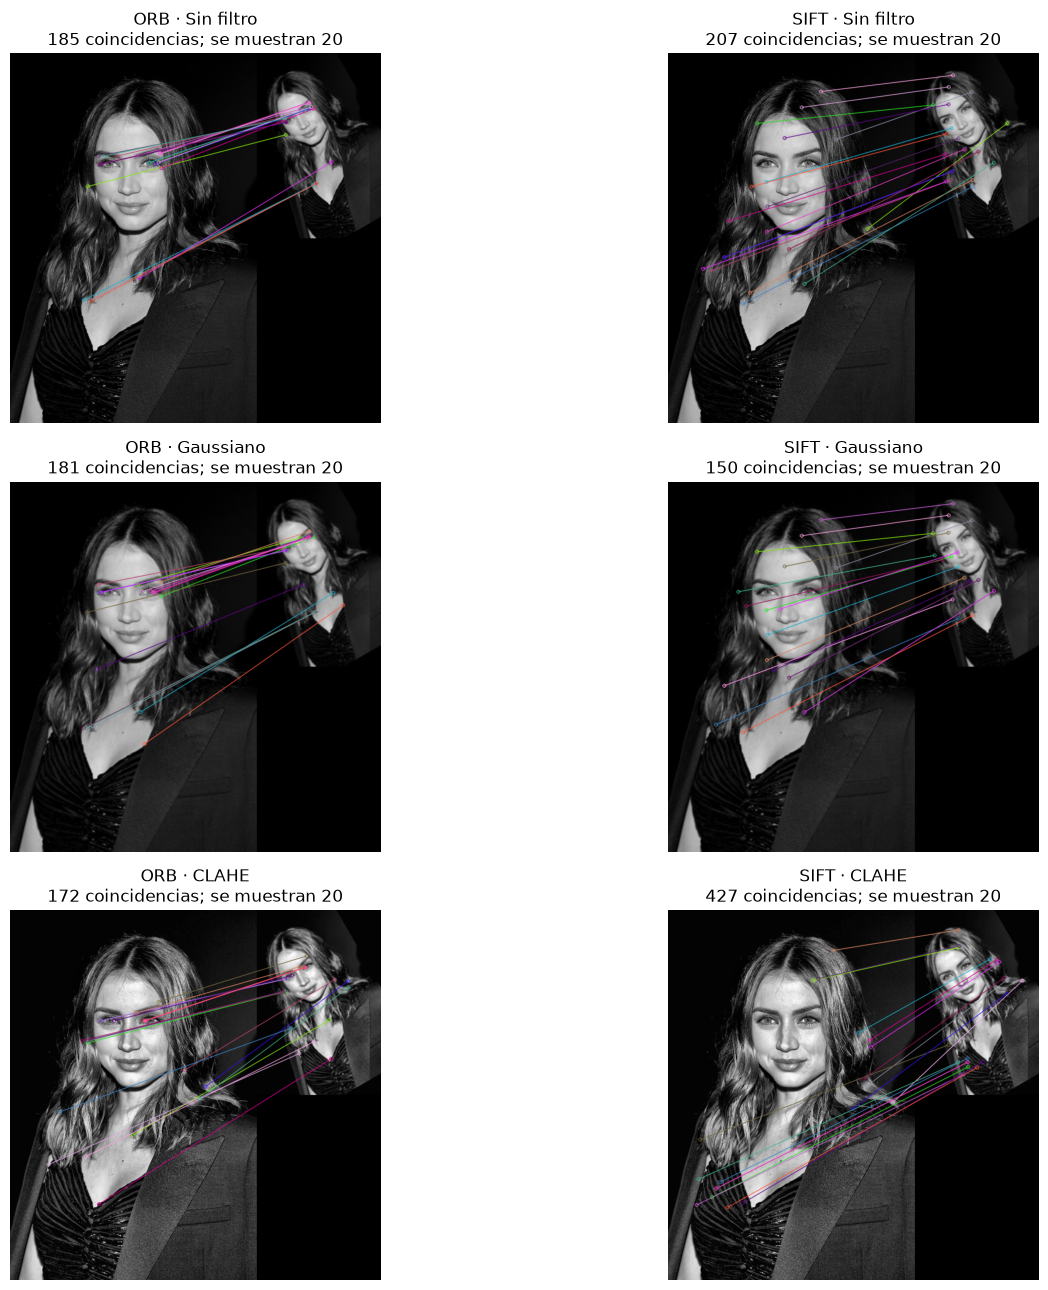

In [10]:
def matching(referencia, copia, metodo):
    if metodo == 'ORB':
        detector, norma = cv2.ORB_create(), cv2.NORM_HAMMING
    elif metodo == 'SIFT':
        detector, norma = cv2.SIFT_create(), cv2.NORM_L1
    else:
        raise ValueError(f'Método no reconocido: {metodo}')
    kp1, desc1 = detector.detectAndCompute(referencia, None)
    kp2, desc2 = detector.detectAndCompute(copia, None)
    if desc1 is None or desc2 is None:
        matches, estado = [], 'Sin descriptores suficientes'
    else:
        bf = cv2.BFMatcher(norma, crossCheck=True)
        matches = sorted(bf.match(desc1, desc2), key=lambda m: m.distance)
        estado = f'{len(matches)} coincidencias; se muestran {min(20, len(matches))}'
    cv2.setRNGSeed(42)
    dibujo = cv2.drawMatches(referencia, kp1, copia, kp2, matches[:20], None, flags=2)
    return dibujo, estado

fig, axes = plt.subplots(3, 2, figsize=(16, 13))
for fila, (filtro, (referencia, copia)) in enumerate(pares.items()):
    for col, metodo in enumerate(['ORB', 'SIFT']):
        dibujo, estado = matching(referencia, copia, metodo)
        mostrar(axes[fila, col], dibujo, f'{metodo} · {filtro}\n{estado}')
plt.tight_layout()
plt.show()


### Matching entre fotografías

Como última prueba, se compararon dos fotografías de la celebridad mediante ORB y SIFT.

A diferencia del caso anterior, las imágenes provienen de escenas distintas. Las líneas permiten revisar las similitudes locales encontradas, pero no demuestran reconocimiento de la persona ni garantizan correspondencias correctas.

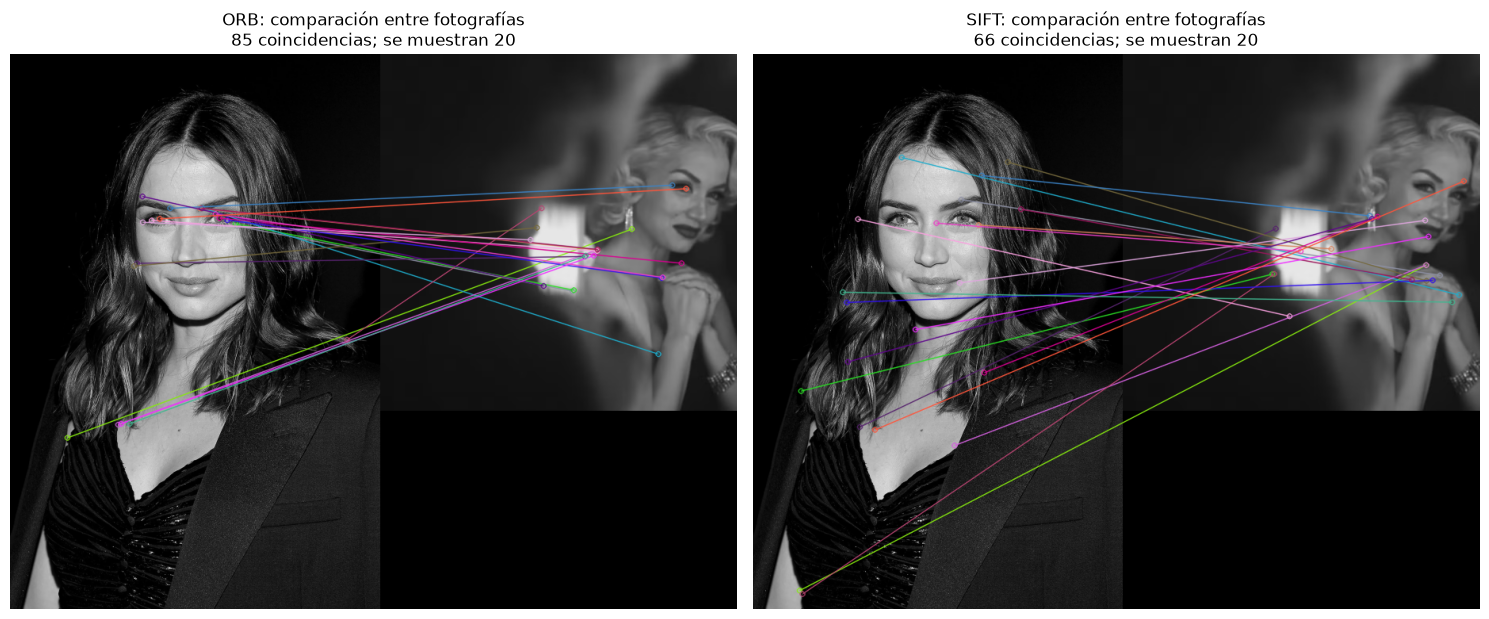

In [11]:
referencia_rgb = ana['ana.jpg']
segunda_rgb = ana['ana mirrored.jpg']
mitad = segunda_rgb.shape[1] // 2
reflejo_rgb = segunda_rgb[:, :mitad].copy()

referencia = cv2.cvtColor(referencia_rgb, cv2.COLOR_RGB2GRAY)
copia = cv2.cvtColor(reflejo_rgb, cv2.COLOR_RGB2GRAY)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metodo in zip(axes, ['ORB', 'SIFT']):
    dibujo, estado = matching(referencia, copia, metodo)
    mostrar(ax, dibujo, f'{metodo}: comparación entre fotografías\n{estado}')
plt.tight_layout()
plt.show()

### Conclusión

Las pruebas permitieron recorrer el proceso de detección de esquinas con Harris y comparar el matching obtenido con ORB y SIFT. El filtrado puede modificar los puntos seleccionados y las coincidencias propuestas, pero una mayor cantidad no significa necesariamente un mejor resultado.

La copia reducida y girada sirvió como referencia para comparar detalles de una misma fotografía. La prueba entre fotografías distintas añadió cambios de apariencia y de escena, por lo que exigió una lectura más cuidadosa de las correspondencias.

En conjunto, el laboratorio muestra la importancia de distinguir entre detección, descripción y matching. Ninguna de estas etapas, por sí sola, equivale al reconocimiento de una persona.